# Type A SFINCS to NPZ: Flat + Sloped DEMs (64x64 + 128x128)

Generates all Type A SFINCS simulations (DEM x rainfall combinations) and
saves each as an npz file.

Each case is labeled with one of five splits, combining two independent
generalization tests:
- **Domain**: 64x64 (seen) vs. 128x128 (unseen)
- **Rainfall**: RP002-RP050 (seen) vs. RP100 (unseen), with RP010 held
  out as validation

| Split | Domain | Rainfall |
|---|---|---|
| `train` | seen | seen |
| `validation` | seen | held out (RP010) |
| `test_unseen_rainfall` | seen | unseen (RP100) |
| `test_unseen_domain` | unseen | seen |
| `test_unseen_domain_and_rainfall` | unseen | unseen (RP100) |

### Imports

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_v3")
sys.path.insert(0, str(PROJECT_ROOT))

from scripts.sfincs_dataset_creation.hyetograph import list_rainfall_files
from scripts.sfincs_dataset_creation.sfincs import run_type_A_case, save_training_npz_type_A

c:\Users\Prof. KN Jha\miniconda3\envs\hydromt-sfincs\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Paths

In [2]:
DEM_FOLDER = PROJECT_ROOT / "data" / "dem" / "Raw_DEMs" / "DEM"        # flat DEMs
SYNTHETIC_FOLDER = PROJECT_ROOT / "data" / "Synthetic_DEMs"            # sloped DEMs + selection CSVs
RAINFALL_FOLDER = PROJECT_ROOT / "data" / "rainfall" / "rainfall_events"

CASE_ROOT = PROJECT_ROOT / "models" / "batch_type_A_cases"
LOG_FOLDER = PROJECT_ROOT / "outputs" / "notebook_logs_type_A"
PROCESSED_FOLDER = PROJECT_ROOT / "outputs" / "batch_type_A_training_npz"

for folder in (CASE_ROOT, LOG_FOLDER, PROCESSED_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)

SFINCS_EXE = PROJECT_ROOT / "exe" / "SFINCS_v2.3.0_mt_Faber_release_exe" / "sfincs.exe"
print("SFINCS executable exists:", SFINCS_EXE.exists())

SFINCS executable exists: True


## Load DEMs

`domain_role` is only the domain axis (64x64 = seen, 128x128 = unseen).
The rainfall axis is applied later, when this list is crossed with
rainfall events to produce the final five-way split.

In [5]:
flat_64 = pd.read_csv(SYNTHETIC_FOLDER / "selected_flat_64x64.csv")
flat_128 = pd.read_csv(SYNTHETIC_FOLDER / "selected_flat_128x128.csv")
sloped = pd.read_csv(SYNTHETIC_FOLDER / "sloped_dem_summary.csv")

flat_64_list = pd.DataFrame({
    "dem_name": flat_64["dem_name"],
    "domain_role": "train",
    "topography": "flat",
    "dem_path": [DEM_FOLDER / name for name in flat_64["dem_name"]],
})

flat_128_list = pd.DataFrame({
    "dem_name": flat_128["dem_name"],
    "domain_role": "test",
    "topography": "flat",
    "dem_path": [DEM_FOLDER / name for name in flat_128["dem_name"]],
})

sloped_list = pd.DataFrame({
    "dem_name": sloped["output_dem"],
    "domain_role": sloped["dataset_role"],
    "topography": "sloped",
    "dem_path": [SYNTHETIC_FOLDER / name for name in sloped["output_dem"]],
})

dem_list = pd.concat([flat_64_list, flat_128_list, sloped_list], ignore_index=True)
print(dem_list.groupby(["domain_role", "topography"]).size())
dem_list.tail(20)

domain_role  topography
test         flat          10
             sloped         6
train        flat          20
             sloped        10
dtype: int64


,dem_name,domain_role,topography,dem_path
26,DEM_15007.txt,test,flat,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
27,DEM_15008.txt,test,flat,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
28,DEM_15009.txt,test,flat,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
29,DEM_15010.txt,test,flat,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
30,DEM_41_sloped_5m_230deg.txt,train,sloped,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
31,DEM_37_sloped_5m_9deg.txt,train,sloped,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
32,DEM_62_sloped_5m_99deg.txt,train,sloped,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
33,DEM_10002_sloped_5m_80deg.txt,train,sloped,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
34,DEM_511_sloped_5m_265deg.txt,train,sloped,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...
35,DEM_38_sloped_10m_243deg.txt,train,sloped,C:\Users\Prof. KN Jha\Desktop\SFINCS_mSWE-GNN_...


## Load Rainfall

In [15]:
rainfall_files = list_rainfall_files(RAINFALL_FOLDER)
print("Rainfall events:", len(rainfall_files))
print(rainfall_files)

Rainfall events: 6
['L3_RP002_temporal_uniform.prcp', 'L3_RP005_temporal_uniform.prcp', 'L3_RP010_temporal_uniform.prcp', 'L3_RP020_temporal_uniform.prcp', 'L3_RP050_temporal_uniform.prcp', 'L3_RP100_temporal_uniform.prcp']


In [17]:
from scripts.sfincs_dataset_creation.hyetograph import read_type_a_prcp

## Split assignment

Combines the DEM's domain_role with the rainfall event's return period to
produce one of five splits. This is deliberately kept as a standalone
function so the same logic can be re-checked or reused later (e.g. when
building dataset_split_type_A.json from run_summary.csv).

In [8]:
def assign_split(domain_role, rainfall_name):
    """Combine domain seen/unseen status with rainfall seen/unseen status."""

    if "RP100" in rainfall_name:
        return "test_unseen_domain_and_rainfall" if domain_role == "test" else "test_unseen_rainfall"
    if "RP010" in rainfall_name:
        return "validation" if domain_role == "train" else "test_unseen_domain"
    return "train" if domain_role == "train" else "test_unseen_domain"

# Quick sanity check across every domain_role x rainfall_name combination.
preview_rows = [
    {"domain_role": domain_role, "rainfall_name": rainfall_name,
     "split": assign_split(domain_role, rainfall_name)}
    for domain_role in ["train", "test"]
    for rainfall_name in rainfall_files
]
pd.DataFrame(preview_rows)

,domain_role,rainfall_name,split
0,train,L3_RP002_temporal_uniform.prcp,train
1,train,L3_RP005_temporal_uniform.prcp,train
2,train,L3_RP010_temporal_uniform.prcp,validation
3,train,L3_RP020_temporal_uniform.prcp,train
4,train,L3_RP050_temporal_uniform.prcp,train
5,train,L3_RP100_temporal_uniform.prcp,test_unseen_rainfall
6,test,L3_RP002_temporal_uniform.prcp,test_unseen_domain
7,test,L3_RP005_temporal_uniform.prcp,test_unseen_domain
8,test,L3_RP010_temporal_uniform.prcp,test_unseen_domain
9,test,L3_RP020_temporal_uniform.prcp,test_unseen_domain


## Full Batch Generation

In [ ]:
def run_one_case(dem_row, rainfall_name):
    """Run one DEM-rainfall SFINCS case and return a summary row. Never raises."""

    split = assign_split(dem_row["domain_role"], rainfall_name)

    try:
        case_dir, metadata = run_type_A_case(
            dem_path=dem_row["dem_path"],
            rainfall_path=RAINFALL_FOLDER / rainfall_name,
            case_root=CASE_ROOT,
            log_folder=LOG_FOLDER,
            sfincs_exe=SFINCS_EXE,
            plot=False,
            verbose=False,
        )

        metadata["domain_role"] = dem_row["domain_role"]
        metadata["topography"] = dem_row["topography"]
        metadata["split"] = split

        npz_path = save_training_npz_type_A(case_dir, PROCESSED_FOLDER, metadata)
        status = "ok"
    except Exception as exc:
        npz_path = None
        status = f"failed: {exc}"  # Catch-all - one bad case shouldn't stop the whole batch.

    return {
        "dem_name": dem_row["dem_name"],
        "domain_role": dem_row["domain_role"],
        "topography": dem_row["topography"],
        "rainfall_event": rainfall_name,
        "split": split,
        "npz_path": str(npz_path) if npz_path else None,
        "status": status,
    }

results = []

for _, dem_row in tqdm(list(dem_list.iterrows()), desc="DEMs"):
    for rainfall_name in rainfall_files:
        result = run_one_case(dem_row, rainfall_name)
        results.append(result)

run_summary = pd.DataFrame(results)
run_summary.to_csv(PROCESSED_FOLDER / "run_summary.csv", index=False)
print(run_summary["status"].value_counts())
print(run_summary["split"].value_counts())

## Build dataset_split_type_A.json

Groups the successful runs by split, so the model_training/HPC side and
the Colab evaluation notebook both read from one authoritative file
rather than re-deriving splits from filenames.

In [ ]:
successful_runs = run_summary[run_summary["status"] == "ok"]

dataset_split = {
    split_name: successful_runs.loc[successful_runs["split"] == split_name, "npz_path"].tolist()
    for split_name in successful_runs["split"].unique()
}

for split_name, npz_paths in dataset_split.items():
    print(f"{split_name}: {len(npz_paths)} events")

with (PROCESSED_FOLDER / "dataset_split_type_A.json").open("w", encoding="utf-8") as file:
    json.dump(dataset_split, file, indent=2)

print("Saved dataset_split_type_A.json")

## Visualization

Spot-check one saved npz per split to confirm the DEM, rainfall, and
water-depth evolution look correct before moving to model training.

In [9]:
def visualize_npz_case(npz_path, interval_hours=3.0):
    """Load one training .npz and show its DEM, rainfall, and water-depth evolution."""

    data = np.load(npz_path, allow_pickle=True)
    metadata = json.loads(str(data["metadata"].item()))

    dem_grid = data["dem"]
    water_depth = data["water_depth"]
    model_time_seconds = data["model_time_seconds"]
    rainfall_time_seconds = data["rainfall_time_seconds"]
    rain_mmhr = data["rain_mmhr"]

    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(dem_grid, origin="lower", cmap="terrain")
    fig.colorbar(image, ax=ax, label="Elevation (m)")
    ax.set_title(f"DEM: {metadata['case_name']} (split={metadata.get('split')})")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.step(rainfall_time_seconds / 3600.0, rain_mmhr, where="post", linewidth=2)
    ax.set_title(f"Rainfall: {metadata['rainfall_name']}")
    ax.set_xlabel("Time (hours)")
    ax.set_ylabel("Rainfall (mm/hr)")
    ax.grid(alpha=0.3)
    plt.show()

    dt_out_seconds = float(model_time_seconds[1] - model_time_seconds[0])
    hours_per_frame = dt_out_seconds / 3600
    frame_step = round(interval_hours / hours_per_frame)
    frames = list(range(0, len(water_depth), frame_step))

    columns = 4
    rows = int(np.ceil(len(frames) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(10, 2.5 * rows), constrained_layout=True, squeeze=False)
    axes = axes.flatten()
    max_depth = np.nanmax(water_depth)

    for axis, frame in zip(axes, frames):
        image = axis.imshow(water_depth[frame], origin="lower", cmap="Blues", vmin=0, vmax=max_depth)
        axis.set_title(f"{frame * hours_per_frame:g} h")
        axis.set_xticks([])
        axis.set_yticks([])
    for axis in axes[len(frames):]:
        axis.axis("off")

    fig.colorbar(image, ax=axes.tolist(), label="Water depth (m)")
    fig.suptitle(f"Flood evolution: {metadata['case_name']}")
    plt.show()



In [10]:
PROCESSED_FOLDER

WindowsPath('C:/Users/Prof. KN Jha/Desktop/SFINCS_mSWE-GNN_v3/outputs/batch_type_A_training_npz')

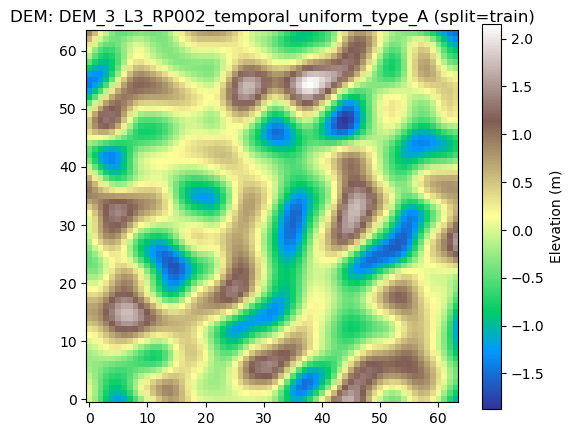

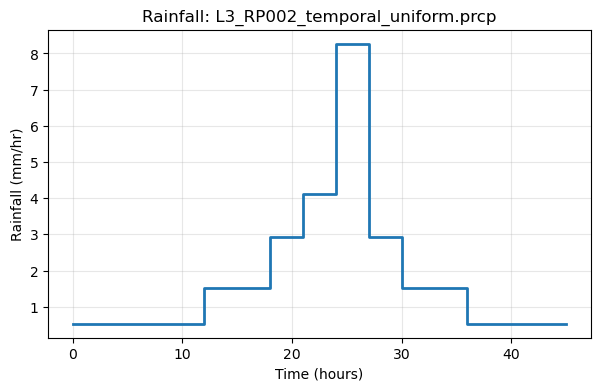

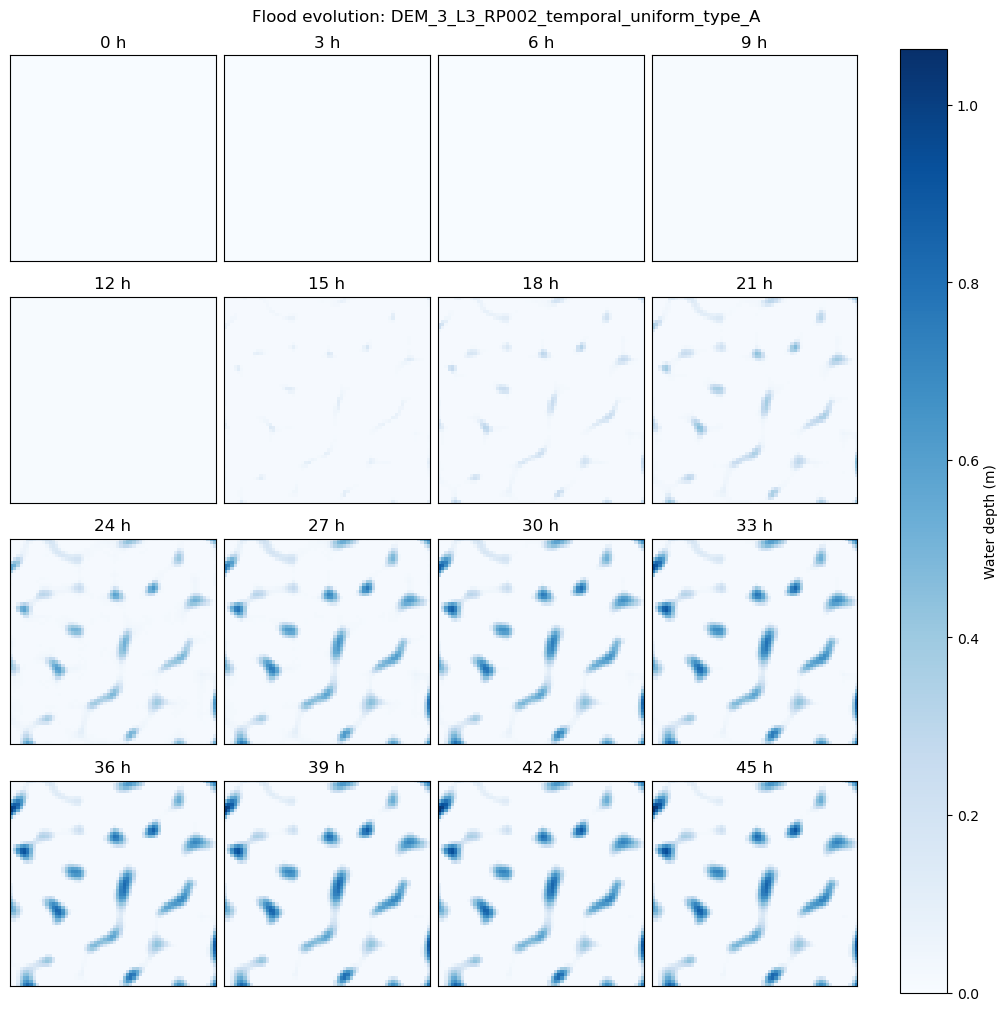

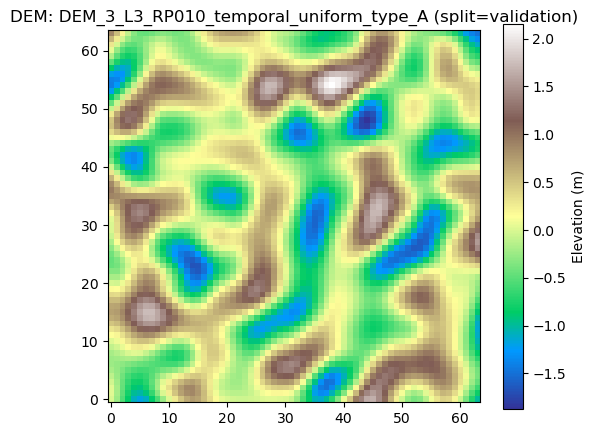

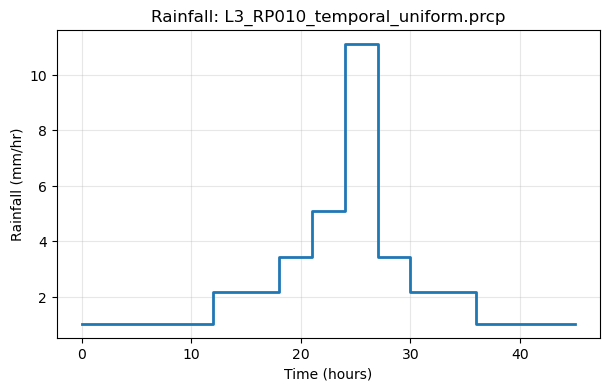

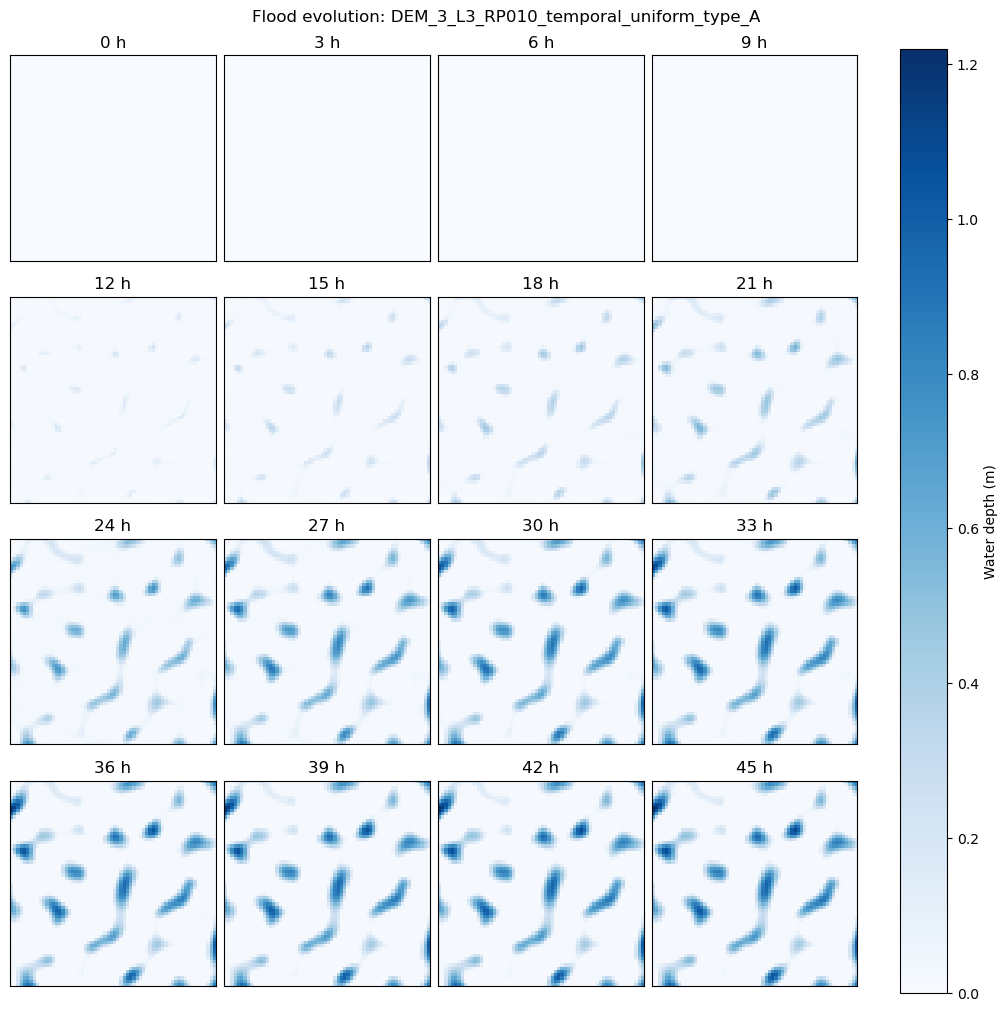

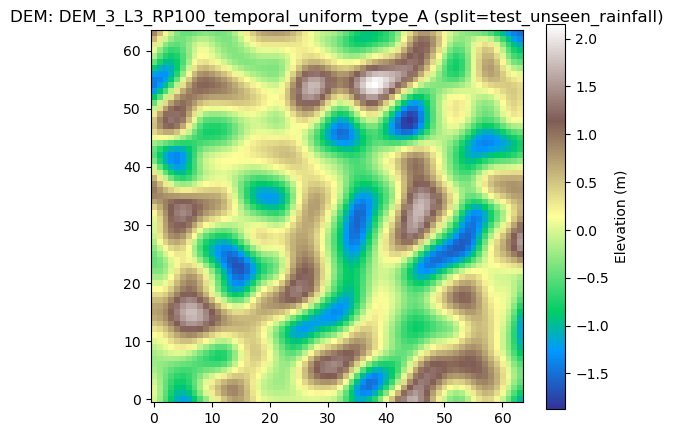

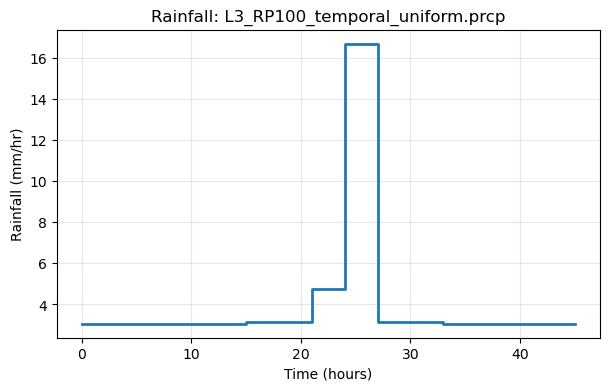

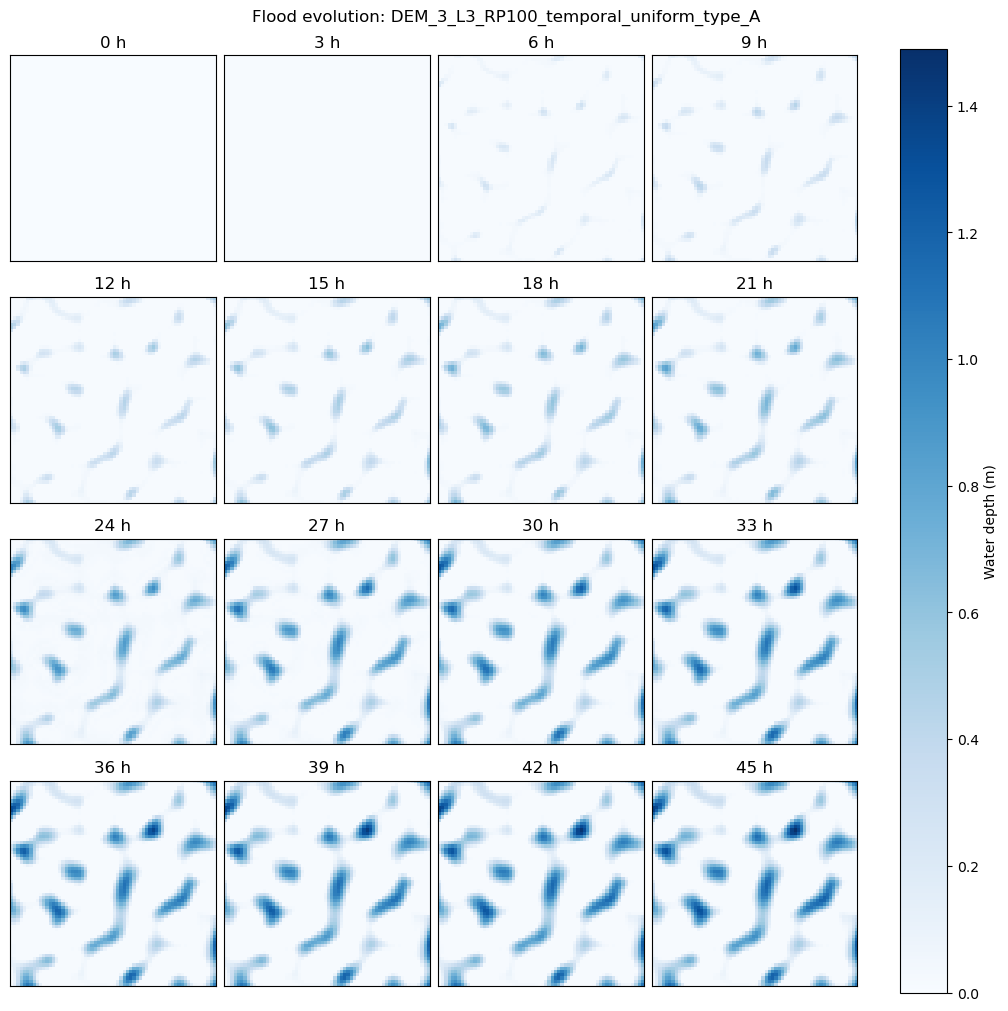

In [11]:
npz_path_flat = PROCESSED_FOLDER / "DEM_3_L3_RP002_temporal_uniform_type_A.npz"
visualize_npz_case(npz_path=npz_path_flat, interval_hours=3)
npz_path_flat = PROCESSED_FOLDER / "DEM_3_L3_RP010_temporal_uniform_type_A.npz"
visualize_npz_case(npz_path=npz_path_flat, interval_hours=3)
npz_path_flat = PROCESSED_FOLDER / "DEM_3_L3_RP100_temporal_uniform_type_A.npz"
visualize_npz_case(npz_path=npz_path_flat, interval_hours=3)

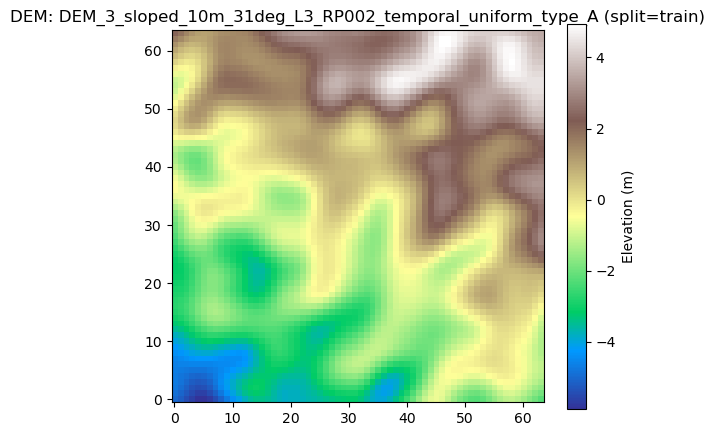

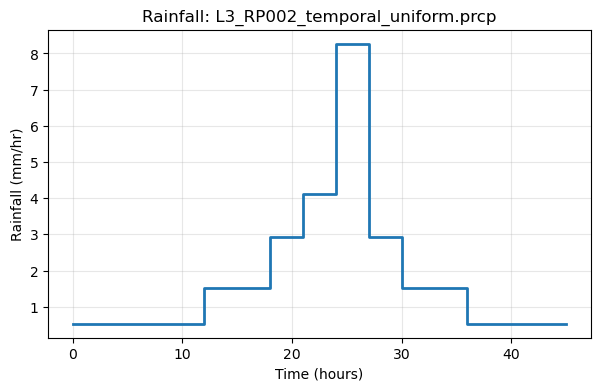

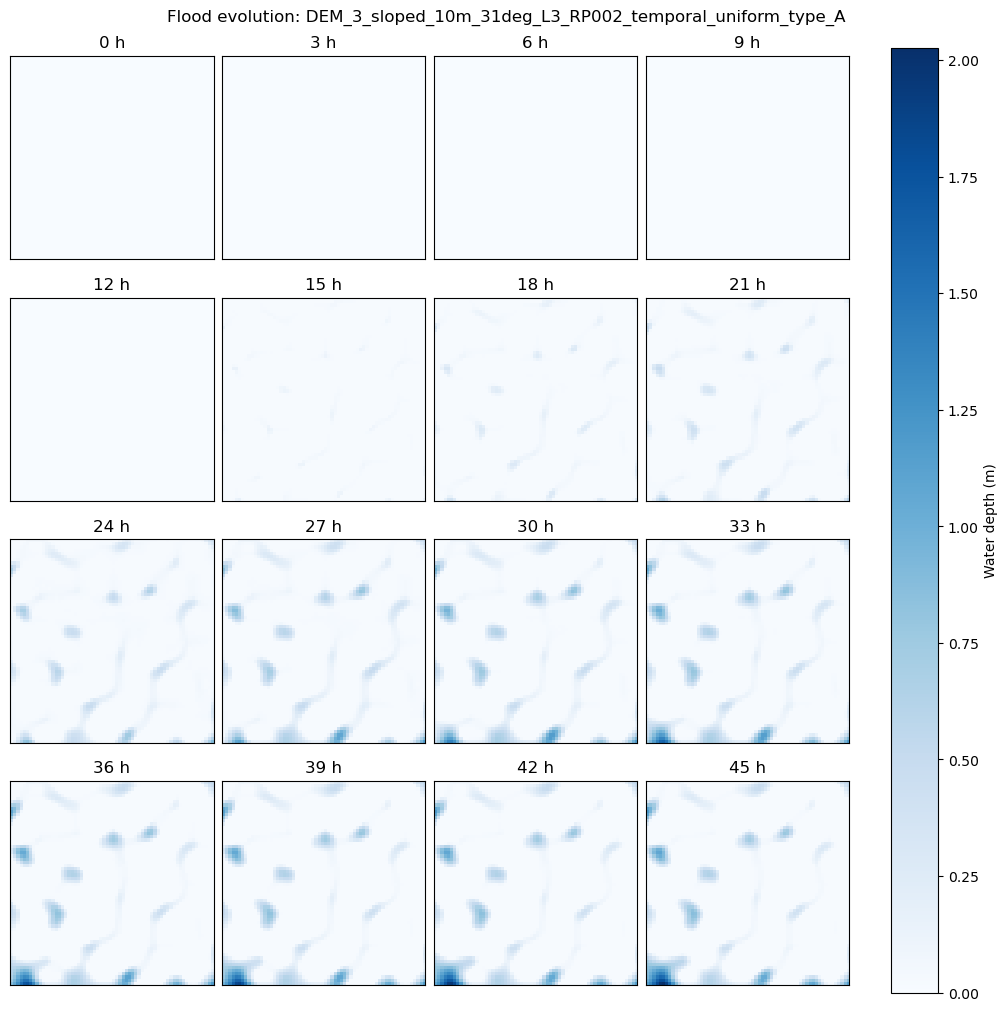

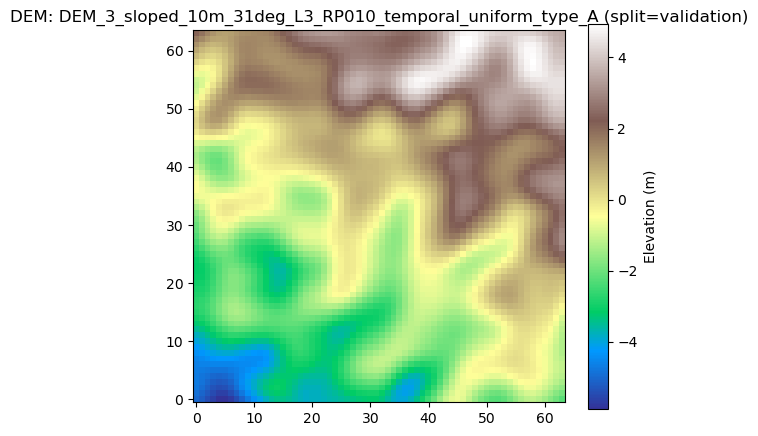

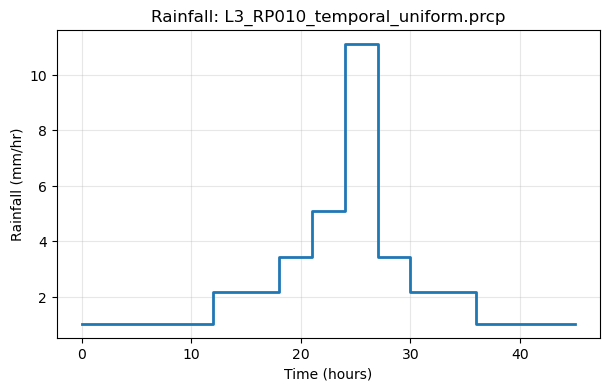

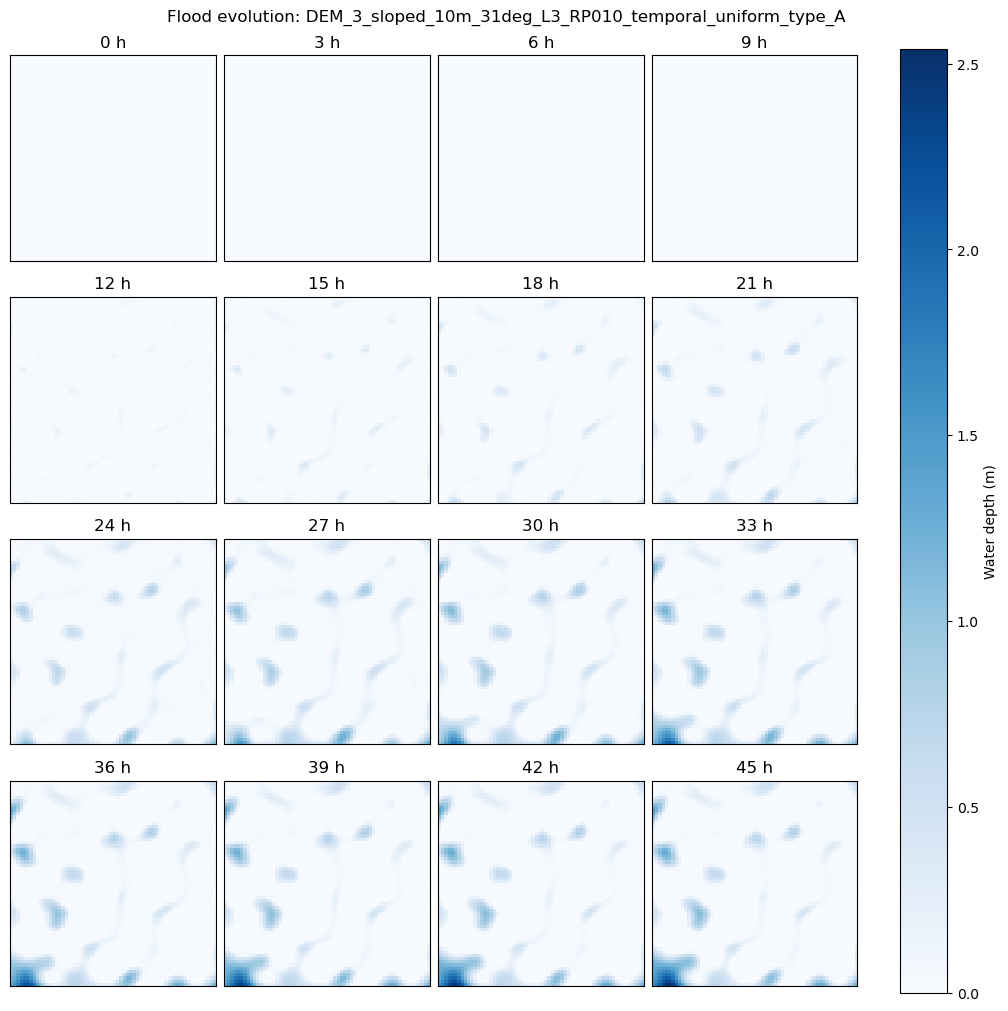

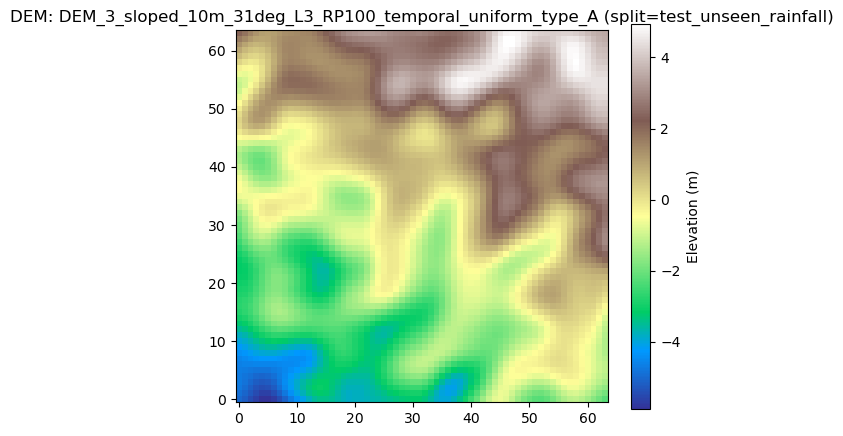

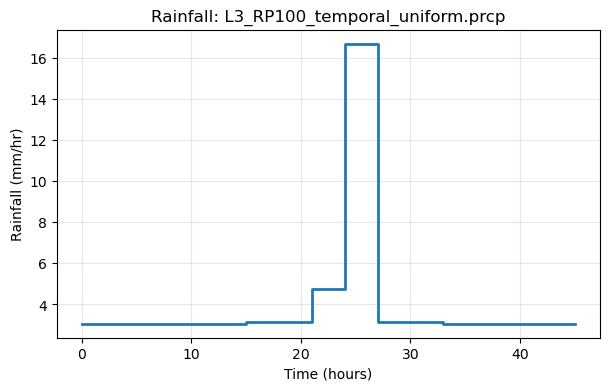

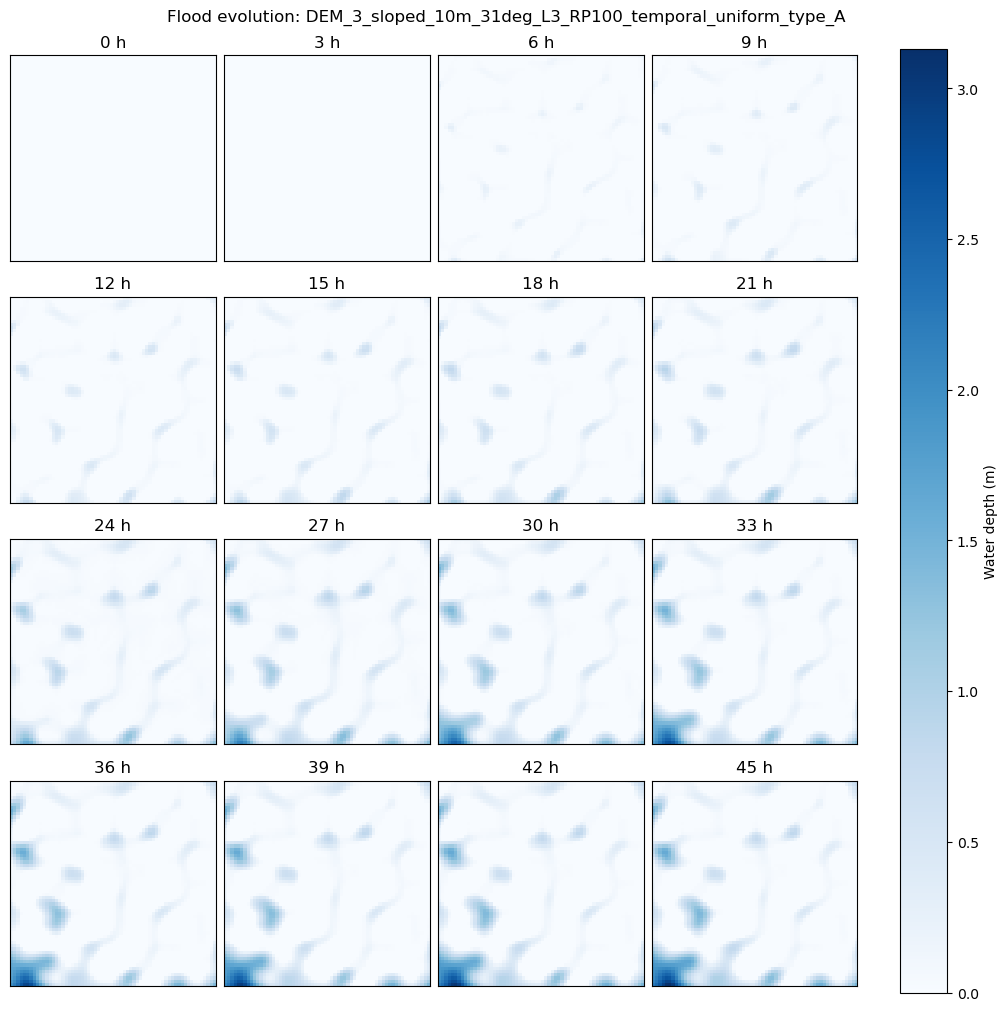

In [12]:
npz_path_sloped = PROCESSED_FOLDER / "DEM_3_sloped_10m_31deg_L3_RP002_temporal_uniform_type_A.npz"
visualize_npz_case(npz_path=npz_path_sloped, interval_hours=3)

npz_path_sloped = PROCESSED_FOLDER / "DEM_3_sloped_10m_31deg_L3_RP010_temporal_uniform_type_A.npz"
visualize_npz_case(npz_path=npz_path_sloped, interval_hours=3)

npz_path_sloped = PROCESSED_FOLDER / "DEM_3_sloped_10m_31deg_L3_RP100_temporal_uniform_type_A.npz"
visualize_npz_case(npz_path=npz_path_sloped, interval_hours=3)